In [1]:
# 데이터 가져오기

# 데이터 전처리

# 데이터 분리

# PolynomialFeatures 다항추가
# degree 추가
# 정규화작업

#### # 데이터 학습
# 규제 적용후 데이터 학습
# alpha값 변경후 데이터 학습 확인

# 데이터 예측
# 정확도

In [2]:
# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures  # 다항특성 자동생성
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv('data/MultipleLinearRegressionData.csv')
df.head()
df[['hour','absent']]
data = df.iloc[:,:-2].values
label = df.iloc[:,-1].values
label

array([ 10,   8,  14,  26,  22,  30,  42,  48,  38,  58,  60,  72,  62,
        68,  72,  58,  76,  86,  90, 100])

In [ ]:
# 원핫인코딩 작업 - 다중공선성 : 특정컬럼이 다른 컬럼에 많은 영향을 미칠때
from sklearn.preprocessing import OneHotEncoder # 문자열데이터를 0,1로 이루어진 원핫인코딩으로 변환하기 위한 모듈
place = df['place'].to_numpy().reshape(-1,1) # 문자열(장소)변수를 0,1로 만듬. 더미는 (3-1)=2개 형성()
encoder = OneHotEncoder(sparse_output=False,drop='first') # drop='first :  다중공선성 문제 해결하기 위해 첫번째 카테고리 생략
result = encoder.fit_transform(place)
# data + result 합치기
total_data = np.concatenate((data,result),axis=1) # 두개의 배열을 붙여라. 가로로(axis=1)

In [5]:
# 학습데이터,테스트데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(total_data,label,random_state=42)

In [6]:
lr = LinearRegression()
lr.fit(train_data,train_label)
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print(score)
print(score2)

0.9770255436151457
0.9551480880200326


In [7]:
test_data[0]

array([0.5, 3. , 1. , 0. ])

In [8]:
predict = lr.predict(test_data)
print('예측점수 : ',predict)

예측점수 :  [-1.96441609 84.65989422 65.11068424  8.54709764 38.32995382]


In [10]:
# 위에서 OneHotEncoder를 했기 때문에 필요없는 구문이지만, 
# 만약, OneHotEncoder를 안했을 경우에 작성해야 하는 구문임

# 장소가 3개 이므로 더미는 2개(3-1)를 만듬
# Home 1., 0.
# Library 0., 1.
# Cafe 0., 0.

in_data = input('공부시간, 결석횟수, 장소를 입력하세요. 예) 4.2,1,Cafe')
in_data = in_data.split(',')
out_data = []
out_data.append(float(in_data[0]))
out_data.append(float(in_data[1]))
if in_data[2] == 'Home':
    out_data.append(1.0)
    out_data.append(0.0)
elif in_data[2] == 'Library':
    out_data.append(0.0)
    out_data.append(1.0)
elif in_data[2] == 'Cafe':
    out_data.append(0.0)
    out_data.append(0.0)

result = lr.predict([out_data])
print(f"1개 예측점수 : {result[0]:.2f}점")

1개 예측점수 : 47.20점


In [11]:
result = lr.predict([out_data])
print("1개 예측점수 : ",result)

1개 예측점수 :  [47.19840819]


In [12]:
predict = lr.predict(test_data)
print(predict)

[-1.96441609 84.65989422 65.11068424  8.54709764 38.32995382]


In [13]:
# 원래 input함수를 살리기 위해서 인위적으로 만든 input함수를 지운 것
# del input 

NameError: name 'input' is not defined

In [14]:
train_data

array([[ 3.2,  0. ,  1. ,  0. ],
       [ 5.8,  0. ,  0. ,  0. ],
       [ 2.4,  0. ,  0. ,  0. ],
       [ 8.6,  1. ,  0. ,  1. ],
       [ 7.2,  2. ,  0. ,  0. ],
       [ 6.1,  1. ,  0. ,  0. ],
       [ 1.8,  2. ,  0. ,  0. ],
       [ 5. ,  1. ,  0. ,  0. ],
       [10. ,  0. ,  0. ,  1. ],
       [ 2.6,  2. ,  1. ,  0. ],
       [ 6. ,  3. ,  0. ,  1. ],
       [ 4.4,  0. ,  0. ,  1. ],
       [ 5.3,  2. ,  0. ,  0. ],
       [ 6.2,  1. ,  0. ,  1. ],
       [ 3.9,  0. ,  0. ,  1. ]])

In [15]:
train_data[0]

array([3.2, 0. , 1. , 0. ])

In [ ]:
# 특성추가
poly = PolynomialFeatures(degree=5,include_bias=False)
poly.fit(train_data) # 어떤 조합의 다항식을 만들것인가의 설계도를 짜는 과정(test_data에는 하면 안됨)
train_poly = poly.transform(train_data) # train_data에 적용
test_poly = poly.transform(test_data) # test_data에 적용

In [17]:
# 정규화 규제
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [ ]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
# 적절한 alpha찾기 : random_state는 고정한 상태에서 alpha를 조정해서 찾아야 함

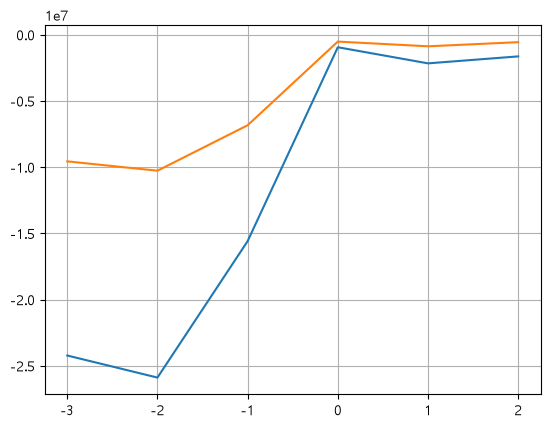

In [19]:
plt.plot(np.log10(alpha_list),train_score)
plt.plot(np.log10(alpha_list),test_score)
plt.grid()
plt.show()

In [20]:
ridge = Ridge(alpha=1)
ridge.fit(train_scaled,train_label)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to

In [21]:

score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print(score)
print(score2)


0.9848303271412874
-5.615895485914004


In [22]:
train_data[0]

array([3.2, 0. , 1. , 0. ])

In [23]:
lr = LinearRegression()
lr.fit(train_data,train_label)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[10.67,-1.18,-7.33,-3.1 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.587
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[8.67,3.75,1.66,1.17]"


In [24]:
# 공부시간 : 4.2, 결석 : 1, 공부장소 : Cafe
# 예상점수가 얼마인지 예측하시오.

# 예상점수 : 00 점

# predict = ridge.predic

In [25]:
train_data[0]

array([3.2, 0. , 1. , 0. ])

In [26]:
train_data.shape

(15, 4)

In [27]:
print(lr.n_features_in_)

4


In [28]:
predict = lr.predict(test_data)
print(predict)
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print(score)
print(score2)

[-1.96441609 84.65989422 65.11068424  8.54709764 38.32995382]
0.9770255436151457
0.9551480880200326


In [29]:
data = df.iloc[:,:-2].values
label = df.iloc[:,-1].values
label

array([ 10,   8,  14,  26,  22,  30,  42,  48,  38,  58,  60,  72,  62,
        68,  72,  58,  76,  86,  90, 100])

In [30]:
# 2. 훈련데이터, 테스트데이터 분리
train_data, test_data, train_label, test_label = train_test_split(
 data, label, random_state=42, test_size=0.2
)

In [31]:
# 3. 다항 특성 자동 생성
poly = PolynomialFeatures(degree=5, include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)


In [32]:
print(poly.get_feature_names_out())

['x0' 'x1' 'x0^2' 'x0 x1' 'x1^2' 'x0^3' 'x0^2 x1' 'x0 x1^2' 'x1^3' 'x0^4'
 'x0^3 x1' 'x0^2 x1^2' 'x0 x1^3' 'x1^4' 'x0^5' 'x0^4 x1' 'x0^3 x1^2'
 'x0^2 x1^3' 'x0 x1^4' 'x1^5']


In [33]:
# 4. 표준화
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)


In [34]:
# 5. 릿지 회귀 - 규제 강도 탐색
train_score = []
test_score = []
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled, train_label)
    train_score.append(ridge.score(train_scaled, train_label))
    test_score.append(ridge.score(test_scaled, test_label))


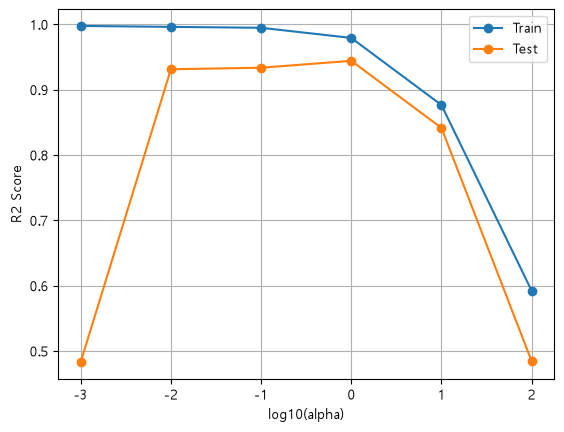

In [35]:
# 6. alpha별 성능 그래프
plt.plot(np.log10(alpha_list), train_score, marker='o')
plt.plot(np.log10(alpha_list), test_score, marker='o')
plt.xlabel('log10(alpha)')
plt.ylabel('R2 Score')
plt.legend(['Train', 'Test'])
plt.grid()
plt.show()

In [ ]:
ridge = Ridge(alpha=1)
ridge.fit(train_scaled, train_label)
print('[최종 모델 성능]')
print('훈련 정확도:', ridge.score(train_scaled, train_label))
print('테스트 정확도:', ridge.score(test_scaled, test_label))


In [ ]:
# 9. 예측 및 오차 확인
result = ridge.predict(test_scaled)
mae = mean_absolute_error(test_label, result)
print('평균 절대 오차(MAE):', mae)

In [ ]:
lr = LinearRegression()
lr.fit(train_poly,train_label)
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print(score)
print(score2)
